In [3]:
import numpy as np
import torch
import torch.nn as nn
import numpy as np
import snntorch as snn
from snntorch import utils
from snntorch import spikegen, surrogate
import snntorch.functional as SF
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader

# -------------- Parameters -----------------------
time_steps = 39512

class plot():
    def plotxy(
        series_list,
        index=None,
        title="",
        xlabel="time stamps",
        ylabel="",
        figsize=(14, 7),
        axhline=None,
        show_legend=True,
        disable_scietific_format = False,
    ):
        plt.figure(figsize=figsize), 
        
        for series  in series_list: 
            y_vals = np.asarray(series["y"])
            if index is not None:
                y_vals = y_vals[:index]
                
            plt.plot(
            y_vals,
            label=series.get("label"),
            color=series.get("color", "#0275D8"),
            linewidth=series.get("linewidth", 1.5),
            alpha=series.get("alpha", 1.0),
            linestyle=series.get("linestyle", "-"),)
        plt.xlabel(xlabel)
        plt.ylabel(ylabel)
        if disable_scietific_format == True:
            plt.ticklabel_format(style="plain", useOffset=False, axis="both")
        if axhline is not None:
            plt.axhline(axhline, color="black", linestyle="--", alpha=0.5)

        if show_legend:
            plt.legend()
        plt.show()
        
        
        
    def plot_spikes(
        series_list,
        index=None,
        value = 1.0,
        title="",
        xlabel="time stamps",
        ylabel="Spikes",
        figsize=(14, 7),
        axhline=None,
        show_legend=True,
        disable_scietific_format=False,
        
    ):
        plt.figure(figsize=figsize), 
        
        for series in series_list:
            
            y_spikes = np.asarray(series["y"])
            if index is not None:
                y_spikes = y_spikes[:index]
            
            spike_point = np.atleast_1d(y_spikes)
            spike_point = np.where(y_spikes == value)[0]
            plt.vlines(
                spike_point,
                ymax=series.get("ymax", 0.5),
                ymin=series.get("ymin", 1.5),
                label=series.get("label"),
                color=series.get("color", "red"),
                linewidth=series.get("linewidth", 1.5),
                alpha=series.get("alpha", 1.0),
                linestyle=series.get("linestyle", "-"),
           )
            
        plt.title(title)
        plt.xlabel(xlabel)
        plt.ylabel(ylabel)
        
        if disable_scietific_format == True:
            plt.ticklabel_format(style="plain", useOffset=False, axis="both")
        if axhline is not None:
            plt.axhline(axhline, color="black", linestyle="--", alpha=0.5)

        if show_legend:
            plt.legend()
        plt.show()
        

def test_accuracy(data_loader, net, num_steps, device, population_code=False, num_classes=False):
  with torch.no_grad():
    total = 0
    acc = 0
    net.eval()

    data_loader = iter(data_loader)
    for data, targets in data_loader:
      data = data.to(device)
      targets = targets.to(device)
      utils.reset(net)
      spk_rec, _ = net(data)

      if population_code:
        acc += SF.accuracy_rate(spk_rec.unsqueeze(0), targets, population_code=True, num_classes=10) * spk_rec.size(1)
      else:
        acc += SF.accuracy_rate(spk_rec, targets) * spk_rec.size(1)

      total += spk_rec.size(1)

  return acc/total


        
plot_xy = plot.plotxy
plot_spike  = plot.plot_spikes
 

In [2]:
"""
Two figures for the paper:

  Part A: I-V pinched hysteresis loop for a SINGLE physical memristor.
          Uses the standard HP TiO2 thin-film memristor model
          (Strukov, Snider, Stewart & Williams, "The missing memristor found",
          Nature 453, 80-83, 2008), with Joglekar's window function to keep
          the state variable bounded. This is a device-physics model -- it is
          NOT derived from your MemristorCrossbar code, since that code has no
          voltage/current dynamics. Cite Strukov et al. 2008 for this figure.

  Part B: Memristance variance of a SINGLE RRAM cell as modeled by YOUR actual
          MemristorCrossbar (D2D + C2C + quantization), converted from
          normalized conductance into an illustrative physical resistance
          range. This one IS your model -- cite yourself / your Methods
          section for this figure, not Strukov et al.
"""

import numpy as np
import matplotlib.pyplot as plt
import torch

plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "DejaVu Serif", "Computer Modern Roman"]


# ======================================================================
# PART A: I-V pinched hysteresis loop (HP memristor device model)
# ======================================================================

def hp_memristor_iv(V0=1.0, freq=1.0, R_on=100.0, R_off=16000.0, D=10e-9,
                     k=15000.0, p=5, x0=0.3, n_cycles=1, steps_per_cycle=4000):
    """
    Simulates a single HP TiO2 memristor driven by V(t) = V0*sin(2*pi*f*t).

    State variable x in [0,1] represents the normalized width of the doped
    (low-resistance) region. Memristance (resistance) is a linear
    interpolation between R_on (fully doped) and R_off (fully undoped):

        M(x) = R_on * x + R_off * (1 - x)

    State dynamics (voltage-controlled, with Joglekar window f(x) to prevent
    x from leaving [0,1] and to model nonlinear ion-drift boundary effects):

        dx/dt = k * i(t) * f(x),   f(x) = 1 - (2x - 1)**(2p)
        i(t)  = V(t) / M(x)

    NOTE: k folds together the physical constants (mu_v * R_on / D**2) from
    the original Strukov et al. formulation. We report it directly (rather
    than mu_v/D separately) because with textbook SI values (mu_v~1e-14
    m^2/V/s, D~10nm) the ion-drift timescale is far faster than a human-scale
    excitation frequency and the loop collapses to a straight line; k=15000
    here is chosen (consistent with how most tutorial/simulation
    implementations do it) purely so the loop is visible at freq=0.5-2 Hz --
    state this in your figure caption rather than presenting k as a measured
    physical constant.
    """
    T = n_cycles / freq
    dt = T / (n_cycles * steps_per_cycle)
    n_steps = n_cycles * steps_per_cycle

    t = np.linspace(0, T, n_steps)
    V = V0 * np.sin(2 * np.pi * freq * t)

    x = np.zeros(n_steps)
    x[0] = x0
    I = np.zeros(n_steps)

    for n in range(n_steps - 1):
        M = R_on * x[n] + R_off * (1 - x[n])
        I[n] = V[n] / M
        f_x = 1 - (2 * x[n] - 1) ** (2 * p)          # Joglekar window
        dx = k * I[n] * f_x * dt
        x[n + 1] = np.clip(x[n] + dx, 0.0, 1.0)

    M_last = R_on * x[-1] + R_off * (1 - x[-1])
    I[-1] = V[-1] / M_last

    return t, V, I, x


def plot_iv_curve(save_path="memristor_iv_curve1.pdf"):
    fig, ax = plt.subplots(figsize=(6, 5.5), dpi=600)

    # Plot at a couple of frequencies to show the classic result:
    # the pinched loop narrows toward a straight line (linear resistor)
    # as frequency increases -- a well-known memristor fingerprint.
    for freq, color, label in [(0.5, "#005b96", "f = 0.5 Hz"),
                                (2.0, "#d95f02", "f = 2.0 Hz")]:
        t, V, I, x = hp_memristor_iv(V0=1.0, freq=freq)
        ax.plot(V, I * 1000, color=color, linewidth=2, label=label)  # mA for readability

    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linewidth=0.8)
    ax.set_xlabel("Voltage (V)", fontweight="bold")
    ax.set_ylabel("Current (mA)", fontweight="bold")
    ax.set_title("Pinched I-V Hysteresis Loop\n(single HP TiO$_2$ memristor model)",
                  fontweight="bold")
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.legend(frameon=True, edgecolor="black")
    fig.tight_layout()
    fig.savefig(save_path, format="pdf", bbox_inches="tight")
    print(f"Saved I-V curve to {save_path}")
    plt.close(fig)


# ======================================================================
# PART A2: Memristance M(t) under a PULSED voltage (the direct "memory" plot)
# ======================================================================

def pulse_train(t, pulse_amp=1.0, pulse_width=0.05, gap=0.05, pattern=None):
    """Builds a square-wave voltage pulse train. `pattern` is a list of
    (sign, n_pulses) pairs, e.g. [(+1, 4), (-1, 4)] = 4 SET pulses then
    4 RESET pulses. Each pulse is `pulse_width` seconds high, then `gap`
    seconds at 0V before the next pulse."""
    if pattern is None:
        pattern = [(+1, 4), (-1, 4)]
    V = np.zeros_like(t)
    period = pulse_width + gap
    idx = 0
    time_cursor = 0.0
    for sign, n in pattern:
        for _ in range(n):
            mask = (t >= time_cursor) & (t < time_cursor + pulse_width)
            V[mask] = sign * pulse_amp
            time_cursor += period
    return V


def simulate_memristance_under_pulses(R_on=100.0, R_off=16000.0, k=15000.0, p=5,
                                       x0=0.5, pulse_amp=1.0, pulse_width=0.05, gap=0.05,
                                       pattern=None, steps_per_sec=20000):
    if pattern is None:
        pattern = [(+1, 4), (-1, 4)]
    n_pulses = sum(n for _, n in pattern)
    T = n_pulses * (pulse_width + gap)
    n_steps = int(T * steps_per_sec)
    t = np.linspace(0, T, n_steps)
    dt = t[1] - t[0]
    V = pulse_train(t, pulse_amp, pulse_width, gap, pattern)

    x = np.zeros(n_steps)
    x[0] = x0
    M = np.zeros(n_steps)

    for n in range(n_steps - 1):
        M[n] = R_on * x[n] + R_off * (1 - x[n])
        I_n = V[n] / M[n]
        f_x = 1 - (2 * x[n] - 1) ** (2 * p)
        dx = k * I_n * f_x * dt
        x[n + 1] = np.clip(x[n] + dx, 0.0, 1.0)
    M[-1] = R_on * x[-1] + R_off * (1 - x[-1])

    return t, V, M, x


def plot_memristance_vs_time(save_path="memristance_vs_time1.pdf"):
    t, V, M, x = simulate_memristance_under_pulses(
        # A HIGH-FREQUENCY pulse train (many short pulses) instead of a few
        # large ones. Physically this is the same SET/RESET switching, just
        # sampled finely enough that the underlying staircase (each individual
        # pulse nudging M by a small amount) blends into a visually smooth
        # curve -- useful when you want to emphasize the overall trend rather
        # than individual switching events.
        pattern=[(+1, 150), (-1, 150)],
        pulse_amp=0.6, pulse_width=0.0008, gap=0.0013,
    )

    fig, ax2 = plt.subplots(figsize=(7, 4.5), dpi=600)

    ax2.plot(t, M / 1e3, color="#005b96", linewidth=2)
    ax2.set_xlabel("Time (s)", fontweight="bold")
    ax2.set_ylabel("Memristance (k$\\Omega$)", fontweight="bold")
    ax2.set_title("Memristance Response to a Programming Pulse Train\n"
                   "(150 SET + 150 RESET pulses)", fontweight="bold")
    ax2.grid(True, linestyle=":", alpha=0.5)
    ax2.axvspan(t[0], t[len(t)//2], color="#005b96", alpha=0.05)
    ax2.axvspan(t[len(t)//2], t[-1], color="#d95f02", alpha=0.05)
    ax2.text(t[len(t)//4], M.max()/1e3, "SET pulses", ha="center", va="bottom", fontsize=9, color="#005b96")
    ax2.text(t[3*len(t)//4], M.max()/1e3, "RESET pulses", ha="center", va="bottom", fontsize=9, color="#d95f02")

    fig.tight_layout()
    fig.savefig(save_path, format="pdf", bbox_inches="tight")
    print(f"Saved memristance-vs-time plot to {save_path}")
    print(f"  M starts at {M[0]/1e3:.2f} k-ohm, "
          f"drops to {M.min()/1e3:.2f} k-ohm after SET pulses, "
          f"rises to {M.max()/1e3:.2f} k-ohm after RESET pulses")
    plt.close(fig)


# ======================================================================
# PART B: Memristance variance of a single RRAM cell (YOUR crossbar model)
# ======================================================================

# --- copy of your actual model, so this plot reflects your real code ---
class STEQuantize(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, num_levels):
        if num_levels is None or num_levels <= 1:
            return x
        scaled = x * (num_levels - 1)
        return torch.round(scaled) / (num_levels - 1)

    @staticmethod
    def backward(ctx, grad_output):
        return grad_output, None


def sample_single_device_conductance(g_programmed, num_levels=16, noise_std=0.05,
                                      d2d_factor=1.0, n_reads=2000):
    """
    Simulates repeatedly READING one already-programmed RRAM device
    (fixed target conductance g_programmed, fixed D2D factor for THIS
    device) across many cycles, exactly as your MemristorCrossbar's
    quantization + C2C noise steps do.
    """
    g = torch.full((n_reads,), g_programmed) * d2d_factor
    g = torch.clamp(g, 0.0, 1.0)
    g_q = STEQuantize.apply(g, num_levels)
    g_noisy = torch.clamp(g_q + torch.randn(n_reads) * noise_std, 0.0, 1.0)
    return g_noisy.numpy()


def plot_memristance_variance(save_path="memristance_variance1.pdf",
                               R_on=1e3, R_off=1e5,
                               g_programmed=0.5, num_levels=16, noise_std=0.05):
    """
    Converts normalized conductance g in [0,1] to an illustrative physical
    resistance range [R_on, R_off] via M = R_off - g*(R_off - R_on), so the
    plot reads in Ohms. R_on/R_off here are ASSUMED illustrative values --
    replace with your actual device's datasheet/literature values before
    using this in the paper.
    """
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), dpi=600)

    # (1) Distribution across repeated reads of ONE device (C2C + quantization only)
    g_single = sample_single_device_conductance(g_programmed, num_levels, noise_std, d2d_factor=1.0)
    M_single = R_off - g_single * (R_off - R_on)

    axes[0].hist(M_single / 1e3, bins=40, color="#005b96", edgecolor="black", alpha=0.85)
    axes[0].set_xlabel("Memristance (k$\\Omega$)", fontweight="bold")
    axes[0].set_ylabel("Count (out of 2000 reads)", fontweight="bold")
    axes[0].set_title("(a) Single device,\nrepeated reads (C2C noise)", fontweight="bold")
    axes[0].grid(True, linestyle=":", alpha=0.5)

    # (2) Distribution across many DIFFERENT devices programmed to the same target (D2D variation)
    torch.manual_seed(0)
    d2d_factors = torch.clamp(1.0 + torch.randn(2000) * 0.05, 0.7, 1.3).numpy()
    g_pop = np.clip(g_programmed * d2d_factors, 0.0, 1.0)
    M_pop = R_off - g_pop * (R_off - R_on)

    axes[1].hist(M_pop / 1e3, bins=40, color="#d95f02", edgecolor="black", alpha=0.85)
    axes[1].set_xlabel("Memristance (k$\\Omega$)", fontweight="bold")
    axes[1].set_ylabel("Count (out of 2000 devices)", fontweight="bold")
    axes[1].set_title("(b) Many devices,\nsame target (D2D variation)", fontweight="bold")
    axes[1].grid(True, linestyle=":", alpha=0.5)

    fig.suptitle(f"Memristance variance around target conductance g={g_programmed}",
                 fontweight="bold", y=1.02)
    fig.tight_layout()
    fig.savefig(save_path, format="pdf", bbox_inches="tight")
    print(f"Saved memristance variance plot to {save_path}")
    print(f"  Single-device (C2C) std: {M_single.std()/1e3:.3f} k-ohm  "
          f"(mean {M_single.mean()/1e3:.3f} k-ohm)")
    print(f"  Cross-device (D2D)  std: {M_pop.std()/1e3:.3f} k-ohm  "
          f"(mean {M_pop.mean()/1e3:.3f} k-ohm)")
    plt.close(fig)


if __name__ == "__main__":
    plot_iv_curve()
    plot_memristance_vs_time()
    plot_memristance_variance()

Saved I-V curve to memristor_iv_curve1.pdf
Saved memristance-vs-time plot to memristance_vs_time1.pdf
  M starts at 8.05 k-ohm, drops to 5.52 k-ohm after SET pulses, rises to 8.05 k-ohm after RESET pulses
Saved memristance variance plot to memristance_variance1.pdf
  Single-device (C2C) std: 5.145 k-ohm  (mean 47.127 k-ohm)
  Cross-device (D2D)  std: 2.529 k-ohm  (mean 50.463 k-ohm)


In [1]:
print("data")

data


In [8]:
### Setup the training Data
# -------------- Parameters -----------------------
import os
import numpy as np
time_steps = 39512
train_file = "data/published/BenchmarkDatasets/BenchmarkDatasets/BenchmarkDatasets/NoAuction/NoAuction_MinMax/NoAuction_MinMax_Training/Train_Dst_NoAuction_MinMax_CF_1.txt"
train_folder = "ata/published/BenchmarkDatasets/BenchmarkDatasets/BenchmarkDatasets/NoAuction/NoAuction_MinMax/"
def get_file(n):
  train_filed = "data/published/BenchmarkDatasets/BenchmarkDatasets/BenchmarkDatasets/NoAuction/NoAuction_MinMax/NoAuction_MinMax_Testing/Test_Dst_NoAuction_MinMax_CF_{}.txt".format(n)
  return train_filed
  
for folders, _, filenames in os.walk(train_folder):
  for filename in filenames:
    print(filename)

data = np.loadtxt(train_file)

for i in range(8):
 
    f = get_file(i + 1)
    d = np.loadtxt(f)
    
    
      
    ask_price = d[0, :]
    bid_price = d[2, :]
    mid_price = (ask_price + bid_price) / 2
    features  = d[:144, :].T 
    labels    = d[146, :].T - 1

    print(len(ask_price))

# ask_price = data[0, :]
# bid_price = data[2, :]
# mid_price = (ask_price + bid_price) / 2
# features  = data[:144, :].T 
# labels    = data[146, :].T - 1

# plot_xy(
#     series_list=[
#         {"y": mid_price, "label": "Positive Spikes"},
#     ],
#     index=time_steps,
#     title="Positive Spikes"
# )


# features_tensor = torch.from_numpy(features).float()
# labels_tensor = torch.from_numpy(labels).float()


# spike = spikegen.delta(features_tensor, threshold=0.01, padding=True, off_spike=True)
# spikes_pos = torch.where(spike > 0, spike, torch.zeros_like(spike))
# spikes_neg = torch.where(spike < 0, torch.abs(spike), torch.zeros_like(spike))

# plot_spike(
#     series_list=[
#         {"y": spikes_pos, "label": "Positive Spikes"},
#     ],
#     index=time_steps,
#     title="Positive Spikes"
# )
# plot_spike(
#     series_list=[
#         {"y": spikes_neg, "label": "Negative Spikes", "color": "blue"},
#     ],
#     index=time_steps,
#     title="Negative Spikes"
# )

# Z = features_tensor[:time_steps, :].numpy()

# X, Y = np.meshgrid(np.arange(time_steps), np.arange(144))
# Z = Z.T

# fig = plt.figure(figsize=(14, 9))
# ax = fig.add_subplot(111, projection="3d")

# surface = ax.plot_surface(X, Y, Z, cmap="viridis", edgecolor="skyblue", linewidth=.2)
# ax.set_xlabel('Time Stamps')
# ax.set_ylabel("Feature Index")
# ax.set_zlabel("Feature Value (Normalized)")
# # ax.view_init(elev=0, azim=180)
# fig.colorbar(surface, shrink=.5, aspect=5)


# plt.show()

38397
28535
37023
34785
39152
37346
55478
52172


In [27]:
# ran = []
# for i in range(8):
 
#     f = get_file(i + 1)
#     d = np.loadtxt(f)
        
#     ask_price = d[0, :]
#     bid_price = d[2, :]
#     mid_price = (ask_price + bid_price) / 2
#     features  = d[:144, :].T 
#     labels    = d[146, :].T - 1
#     ran.append(mid_price)
#     print(len(mid_price))
    
# comparison
print(ran[1].shape, ran[2].shape)
# np.equal(ran[1], ran[2])

(77909,) (106444,)


In [230]:
### Setup the Testing Data
test_file  = "data/published/BenchmarkDatasets/BenchmarkDatasets/BenchmarkDatasets/NoAuction/NoAuction_MinMax/NoAuction_MinMax_Testing/Test_Dst_NoAuction_MinMax_CF_1.txt"

test_data = np.loadtxt(test_file)
features_test  = test_data[:144, :].T 
labels_test    = test_data[146, :].T - 1



features_tensor_test = torch.from_numpy(features_test).float()
labels_tensor_test = torch.from_numpy(labels_test).long()


spike_test = spikegen.delta(features_tensor_test, threshold=0.01, padding=True, off_spike=True)
spikes_pos_test = torch.where(spike_test > 0, spike_test, torch.zeros_like(spike_test))
spikes_neg_test = torch.where(spike_test < 0, torch.abs(spike_test), torch.zeros_like(spike_test))

 
test_inputs = torch.cat((spikes_pos_test, spikes_neg_test), dim=1)
test_dataset = TensorDataset(test_inputs, labels_tensor_test)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

inputs_train = torch.cat((spikes_pos, spikes_neg), dim=1)

dataset = TensorDataset(inputs_train, labels_tensor)

batch_size = 16
# shuffle is set to false to keep the time-series sequence order (took me 3 days to debug ughhh)
train_loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

print(f"dataloader {len(train_loader)}")

dataloader 2470


In [ ]:
# Parameters of the network
num_inputs = 288
num_hidden = 128
num_outputs = 3
beta = .9
num_seps = 25

spike_grad = surrogate.fast_sigmoid(slope=25)

class HFT_Net(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.fc1  = nn.Linear(num_inputs, num_hidden)
        self.lif1 = snn.Leaky(threshold=.5,  beta=beta, spike_grad=spike_grad)
        self.fc2  = nn.Linear(num_hidden, num_outputs)
        self.lif2 = snn.Leaky(threshold=.5, beta=beta, spike_grad=spike_grad)
        
    def forward(self, x):
        mem1 = self.lif1.init_leaky()
        mem2 = self.lif2.init_leaky()
        
        spk2_rec = []
        mem2_rec = []
        
        for step in range(x.shape[0]):
            cur1 = self.fc1(x[step])
            spk1, mem1 = self.lif1(cur1, mem1)
            cur2 = self.fc2(spk1)
            spk2, mem2 = self.lif2(cur2, mem2)
            
            spk2_rec.append(spk2)
            mem2_rec.append(mem2)
            
        return torch.stack(spk2_rec, dim=0), torch.stack(mem2_rec, dim=0)
    

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

net = HFT_Net().to(device)
optimizer = torch.optim.Adam(net.parameters(), lr=2e-4, betas=(0.9, 0.999))
class_weights = torch.tensor([2.0, 0.5, 2.0]).to(device)
loss_fn = SF.ce_rate_loss(weight=class_weights)

num_epochs = 25
loss_hist = []
spk_re = []
for epoch in range(num_epochs):
    net.train()
    
    for batch_idx, (data, targets) in enumerate(train_loader):
        data = data.to(device)
        targets = targets.to(device).long()
        
        data_seq = data.unsqueeze(1) 
        target_seq = targets[-1].unsqueeze(0)
        
        spk_rec, mem_rec = net(data_seq)
        
        loss_val = loss_fn(spk_rec, target_seq)
        optimizer.zero_grad()
        loss_val.backward()
        optimizer.step()
        
        loss_hist.append(loss_val.item())
        
         
        if batch_idx % 50 == 0:
            print(f"Epoch {epoch}, Batch {batch_idx} \tTraining Loss: {loss_val.item():.4f}")
            


NameError: name 'train_loader' is not defined

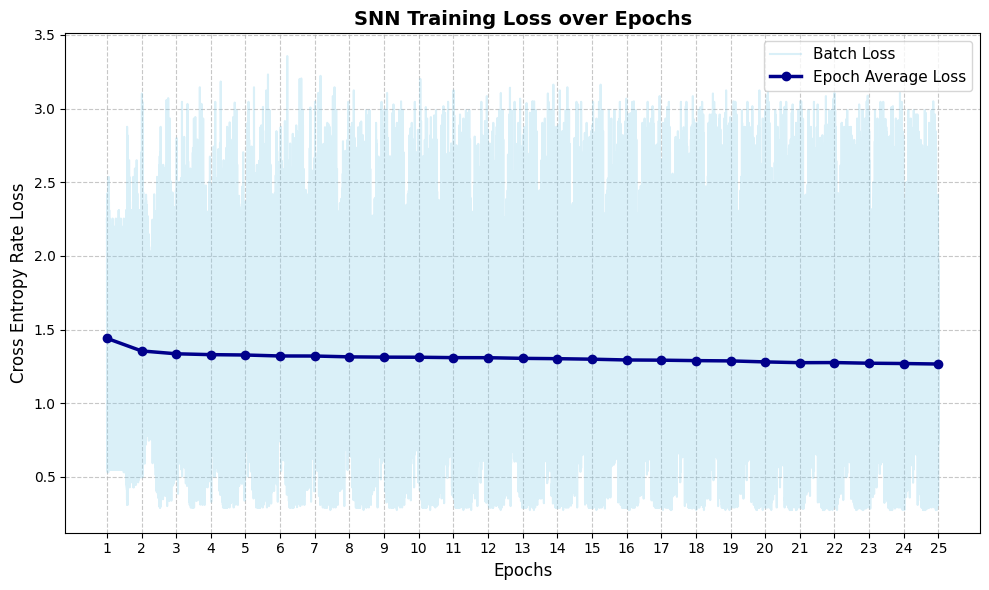

1.3082660411171585
1.3082660411171585
1.3082660411171585
[1.44107843 1.35548628 1.33607983 1.33021504 1.32780551 1.32114356
 1.32088122 1.31521759 1.31325328 1.31267965 1.30996414 1.30952797
 1.30504644 1.30286815 1.2994171  1.294102   1.29268858 1.28968631
 1.2877698  1.28100738 1.2757003  1.27647549 1.27206598 1.26994036
 1.26655066]
[1.35548628 1.33607983 1.33021504 1.32780551 1.32114356 1.32088122
 1.31521759 1.31325328 1.31267965 1.30996414 1.30952797 1.30504644
 1.30286815 1.2994171  1.294102   1.29268858 1.28968631 1.2877698
 1.28100738 1.2757003  1.27647549 1.27206598 1.26994036 1.26655066]


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Calculate how many batches were in a single epoch
batches_per_epoch = len(train_loader)
total_epochs = len(loss_hist) // batches_per_epoch

# 2. Reshape the flat loss list into a 2D array: (Epochs, Batches)
# and calculate the average loss per epoch
loss_array = np.array(loss_hist)[:total_epochs * batches_per_epoch].reshape(total_epochs, batches_per_epoch)

epoch_losses = loss_array.mean(axis=1)

# 3. Create the X-axis values (Epochs 1 to N)
epochs_x = np.arange(1, total_epochs + 1)
batches_x = np.linspace(1, total_epochs, len(loss_hist))

# 4. Plotting
plt.figure(figsize=(10, 6))

# Plot the raw batch loss in the background (faded) to show the actual LOB volatility
plt.plot(batches_x, loss_hist, color='skyblue', alpha=0.3, label='Batch Loss')

# Plot the clean, averaged epoch loss on top
plt.plot(epochs_x, epoch_losses, color='darkblue', linewidth=2.5, marker='o', label='Epoch Average Loss')

# Formatting for a research paper
plt.title("SNN Training Loss over Epochs", fontsize=14, fontweight='bold')
plt.xlabel("Epochs", fontsize=12)
plt.ylabel("Cross Entropy Rate Loss", fontsize=12)
plt.xticks(epochs_x) # Force the X-axis to show whole numbers for epochs
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(loc="upper right", fontsize=11)
plt.tight_layout()

plt.show()


 